X_train shape: (3000, 100, 1), y_train shape: (3000,)


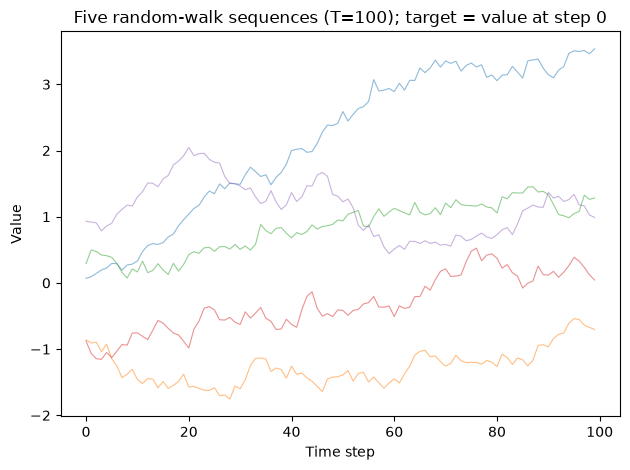

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

rng = np.random.default_rng(3151)

T_SEQ = 100
N_TRAIN = 3000
N_VAL   = 500
SIGMA   = 0.1

def make_walk_data(n, T, sigma, rng):
    x0    = rng.uniform(-1, 1, size=(n,)).astype(np.float32)
    noise = rng.normal(0, sigma, size=(n, T)).astype(np.float32)
    seqs  = np.zeros((n, T), dtype=np.float32)
    seqs[:, 0] = x0
    for t in range(1, T):
        seqs[:, t] = seqs[:, t-1] + noise[:, t]
    # sequences shape: (n, T, 1), targets shape: (n,)
    return seqs[:, :, np.newaxis], x0

X_train, y_train = make_walk_data(N_TRAIN, T_SEQ, SIGMA, rng)
X_val,   y_val   = make_walk_data(N_VAL,   T_SEQ, SIGMA, rng)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

# Quick sanity plot
fig, ax = plt.subplots()
for i in range(5):
    ax.plot(X_train[i, :, 0], alpha=0.5, linewidth=0.8)
ax.set_xlabel("Time step")
ax.set_ylabel("Value")
ax.set_title("Five random-walk sequences (T=100); target = value at step 0")
plt.tight_layout()

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

def make_loaders(X, y, X_v, y_v, bs=128):
    Xt = torch.from_numpy(X);  yt = torch.from_numpy(y)
    Xv = torch.from_numpy(X_v); yv = torch.from_numpy(y_v)
    return (DataLoader(TensorDataset(Xt, yt), batch_size=bs, shuffle=True),
            DataLoader(TensorDataset(Xv, yv), batch_size=256))

train_loader, val_loader = make_loaders(X_train, y_train, X_val, y_val)

H = 32

class SeqModel(nn.Module):
    def __init__(self, rnn_type="rnn", hidden=32):
        super().__init__()
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[rnn_type]
        self.rnn = cls(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
        self.rnn_type = rnn_type
    def forward(self, x):
        out, _ = self.rnn(x)
        last    = out[:, -1, :]   # hidden state at step T-1
        return self.head(last).squeeze(-1)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

models = {name: SeqModel(name, H).to(device) for name in ["rnn", "lstm", "gru"]}
for name, m in models.items():
    print(f"{name.upper():4s}: {count_params(m):,} params")

RNN : 1,153 params
LSTM: 4,513 params
GRU : 3,393 params


In [5]:
def train_model(model, tl, vl, epochs=60, lr=3e-3):      # TODO epochs -> 120
    opt  = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    hist = {"epoch": [], "train_mse": [], "val_mse": []}
    for ep in range(1, epochs + 1):
        model.train()
        t_loss, t_n = 0.0, 0
        for xb, yb in tl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            t_loss += loss.item() * xb.size(0); t_n += xb.size(0)
        model.eval()
        v_loss, v_n = 0.0, 0
        with torch.no_grad():
            for xb, yb in vl:
                xb, yb = xb.to(device), yb.to(device)
                v_loss += loss_fn(model(xb), yb).item() * xb.size(0); v_n += xb.size(0)
        hist["epoch"].append(ep)
        hist["train_mse"].append(t_loss / t_n)
        hist["val_mse"].append(v_loss / v_n)
    return pd.DataFrame(hist)

histories = {name: train_model(m, train_loader, val_loader) for name, m in models.items()}

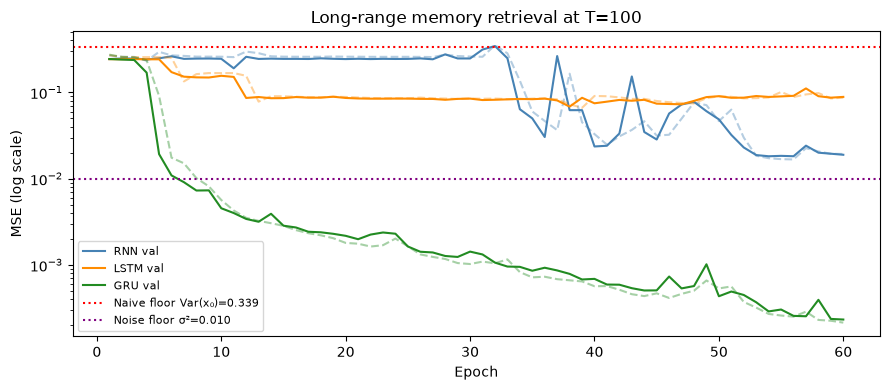

In [6]:
naive_floor = float(np.var(y_train))
noise_floor = SIGMA**2

fig, ax = plt.subplots(figsize=(9, 4))
colours = {"rnn": "steelblue", "lstm": "darkorange", "gru": "forestgreen"}
for name, hist in histories.items():
    ax.plot(hist["epoch"], hist["val_mse"],
            label=f"{name.upper()} val", color=colours[name])
    ax.plot(hist["epoch"], hist["train_mse"],
            linestyle="--", alpha=0.4, color=colours[name])

ax.axhline(naive_floor, color="red",    linestyle=":", linewidth=1.5,
           label=f"Naive floor Var(x₀)={naive_floor:.3f}")
ax.axhline(noise_floor, color="purple", linestyle=":", linewidth=1.5,
           label=f"Noise floor σ²={noise_floor:.3f}")
ax.set_yscale("log")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)")
ax.set_title("Long-range memory retrieval at T=100")
ax.legend(fontsize=8)
plt.tight_layout()

In [7]:
rows = []
for name, hist in histories.items():
    rows.append({
        "Model":         name.upper(),
        "Params":        f"{count_params(models[name]):,}",
        "Final val MSE": round(hist["val_mse"].iloc[-1], 5),
        "Beats naive floor?": "✓" if hist["val_mse"].iloc[-1] < naive_floor else "✗",
        "Approaches noise floor?": "✓" if hist["val_mse"].iloc[-1] < 5 * noise_floor else "✗",
    })
pd.DataFrame(rows)

,Model,Params,Final val MSE,Beats naive floor?,Approaches noise floor?
0,RNN,"1,153",0.01893,✓,✓
1,LSTM,"4,513",0.08873,✓,✗
2,GRU,"3,393",0.00023,✓,✓


In [10]:
from collections import Counter
import re
from datasets import load_dataset
import random


# ── Real SST-2 subsample (5 000 train + 400 validation) ───────────────────────
# Loads from HuggingFace Hub; requires network access.
# The official SST-2 validation split has no labels publicly, so we carve our
# own val set from the training split.

N_SAMPLES  = 5000
VAL_FRAC   = 0.2
MAX_LEN    = 30
VOCAB_SIZE = 5000
EMBED_DIM  = 64

random.seed(3151)
np.random.seed(3151)
torch.manual_seed(3151)
torch.cuda.manual_seed_all(3151)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

raw = (load_dataset("stanfordnlp/sst2", split="train")
       .shuffle(seed=3151)
       .select(range(N_SAMPLES)))

# ── Build a simple word-level vocabulary from this subsample ──────────────────
def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

all_tokens = [tok for ex in raw for tok in tokenize(ex["sentence"])]
vocab_counts = Counter(all_tokens)
# token→index: 0=PAD, 1=UNK, then top (VOCAB_SIZE-2) words
idx2tok = ["<PAD>", "<UNK>"] + [w for w, _ in vocab_counts.most_common(VOCAB_SIZE - 2)]
tok2idx = {w: i for i, w in enumerate(idx2tok)}

def encode(text, max_len=MAX_LEN):
    ids = [tok2idx.get(t, 1) for t in tokenize(text)][:max_len]
    ids += [0] * (max_len - len(ids))          # right-pad with PAD=0
    return ids

X_sst = np.array([encode(ex["sentence"]) for ex in raw], dtype=np.int64)
y_sst = np.array([ex["label"]            for ex in raw], dtype=np.int64)

split = int((1 - VAL_FRAC) * N_SAMPLES)
Xtr_s, Xvl_s = X_sst[:split], X_sst[split:]
ytr_s, yvl_s = y_sst[:split], y_sst[split:]

g = torch.Generator()
g.manual_seed(3151)

sst_train_loader = DataLoader(
    TensorDataset(torch.from_numpy(Xtr_s), torch.from_numpy(ytr_s)),
    batch_size=64, shuffle=True, generator=g)
sst_val_loader = DataLoader(
    TensorDataset(torch.from_numpy(Xvl_s), torch.from_numpy(yvl_s)),
    batch_size=256)

print(f"Train: {Xtr_s.shape}  Val: {Xvl_s.shape}")
print(f"Class balance — train: {np.bincount(ytr_s)}, val: {np.bincount(yvl_s)}")
print(f"Vocab size used: {len(tok2idx)}")

Train: (4000, 30)  Val: (1000, 30)
Class balance — train: [1755 2245], val: [440 560]
Vocab size used: 5000


In [11]:
class SentimentModel(nn.Module):
    def __init__(self, rnn_type="lstm", vocab=VOCAB_SIZE,
                 embed_dim=EMBED_DIM, hidden=64, num_classes=2):
        super().__init__()
        self.embed = nn.Embedding(vocab, embed_dim, padding_idx=0)
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[rnn_type]
        self.rnn  = cls(embed_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.head = nn.Linear(hidden, num_classes)
        self.rnn_type = rnn_type

    def forward(self, x):
        emb  = self.drop(self.embed(x))        # (B, T, E)
        out, _ = self.rnn(emb)
        last = out[:, -1, :]                   # last hidden state
        return self.head(self.drop(last))

sst_models = {n: SentimentModel(n).to(device) for n in ["rnn", "lstm", "gru"]}
for n, m in sst_models.items():
    print(f"{n.upper():4s}: {count_params(m):,} params")

RNN : 328,450 params
LSTM: 353,410 params
GRU : 345,090 params


In [12]:
def train_classifier(model, tl, vl, epochs=10, lr=1e-3, patience=7):
    opt     = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = {"epoch": [], "train_acc": [], "val_acc": [], "val_loss": []}

    best_val_loss = float("inf")
    epochs_no_improve = 0
    for ep in range(1, epochs + 1):
        model.train()
        t_correct, t_n = 0, 0
        for xb, yb in tl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            logits = model(xb)
            loss   = loss_fn(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            t_correct += (logits.argmax(1) == yb).sum().item(); t_n += yb.size(0)

        model.eval()
        v_correct, v_n, v_loss_sum = 0, 0, 0.0
        with torch.no_grad():
            for xb, yb in vl:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                v_loss_sum += loss_fn(logits, yb).item() * yb.size(0)
                v_correct  += (logits.argmax(1) == yb).sum().item(); v_n += yb.size(0)

        if v_loss_sum / v_n < best_val_loss:
            best_val_loss = v_loss_sum / v_n
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break

        hist["epoch"].append(ep)
        hist["train_acc"].append(t_correct / t_n)
        hist["val_acc"].append(v_correct / v_n)
        hist["val_loss"].append(v_loss_sum / v_n)

    return pd.DataFrame(hist)

sst_hists = {n: train_classifier(m, sst_train_loader, sst_val_loader)
             for n, m in sst_models.items()}

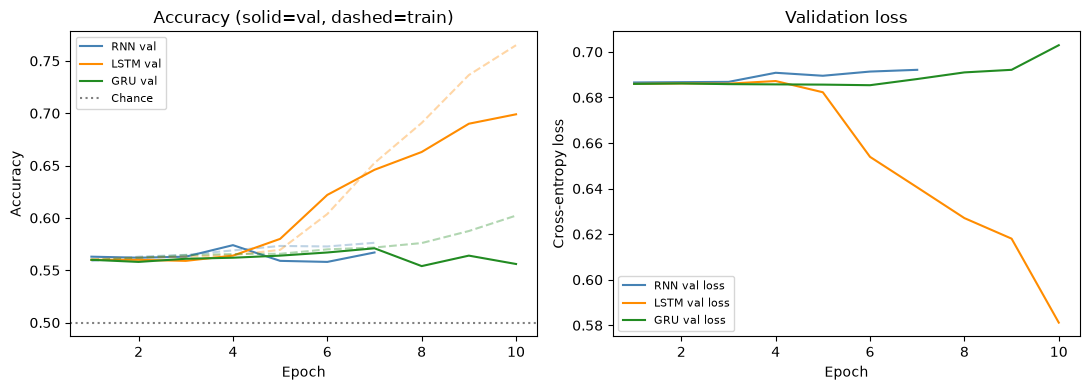

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, hist in sst_hists.items():
    axes[0].plot(hist["epoch"], hist["val_acc"],   label=f"{name.upper()} val",   color=colours[name])
    axes[0].plot(hist["epoch"], hist["train_acc"], linestyle="--", alpha=0.35,    color=colours[name])
    axes[1].plot(hist["epoch"], hist["val_loss"],  label=f"{name.upper()} val loss", color=colours[name])

axes[0].axhline(0.5, color="gray", linestyle=":", label="Chance")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy (solid=val, dashed=train)"); axes[0].legend(fontsize=8)

axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Cross-entropy loss")
axes[1].set_title("Validation loss"); axes[1].legend(fontsize=8)

plt.tight_layout()

In [14]:
rows2 = []
for name, hist in sst_hists.items():
    best_val = hist["val_acc"].max()
    final_gap = hist["train_acc"].iloc[-1] - hist["val_acc"].iloc[-1]
    rows2.append({
        "Model":           name.upper(),
        "Params":          f"{count_params(sst_models[name]):,}",
        "Best val acc":    round(best_val, 3),
        "Train–val gap":   round(final_gap, 3),
    })
pd.DataFrame(rows2)

,Model,Params,Best val acc,Train–val gap
0,RNN,"328,450",0.574,0.009
1,LSTM,"353,410",0.699,0.066
2,GRU,"345,090",0.571,0.046
